# MLP

### Front matter

---
### exercise: resolucao_data
### ai_use: "Gemini no código e formatação do markdown, as análises sobre são minhas."
---

# Exercício 1: Um passo de retropropagação, na mão

Valores iniciais dados:
* $\mathbf{x} = \begin{bmatrix} 0.5000 \\ -0.2000 \end{bmatrix}$, $y = 1.0000$
* $\mathbf{W}^{(1)} = \begin{bmatrix} 0.3000 & -0.1000 \\ 0.2000 & 0.4000 \end{bmatrix}$
* $\mathbf{b}^{(1)} = \begin{bmatrix} 0.1000 \\ -0.2000 \end{bmatrix}$
* $\mathbf{W}^{(2)} = \begin{bmatrix} 0.5000 & -0.3000 \end{bmatrix}$
* $b^{(2)} = 0.2000$
* $\eta = 0.3000$


---

### A — Passagem direta

1. **Pré-ativações da camada oculta ($\mathbf{z}^{(1)}$):**

$$\mathbf{z}^{(1)} = \mathbf{W}^{(1)}\mathbf{x} + \mathbf{b}^{(1)} = \begin{bmatrix} 0.3000(0.5000) + (-0.1000)(-0.2000) + 0.1000 \\ 0.2000(0.5000) + 0.4000(-0.2000) + (-0.2000) \end{bmatrix} = \begin{bmatrix} 0.1500 + 0.0200 + 0.1000 \\ 0.1000 - 0.0800 - 0.2000 \end{bmatrix} = \begin{bmatrix} 0.2700 \\ -0.1800 \end{bmatrix}$$

2. **Ativações da camada oculta ($\mathbf{h}^{(1)}$):**

$$\mathbf{h}^{(1)} = \tanh(\mathbf{z}^{(1)}) = \begin{bmatrix} \tanh(0.2700) \\ \tanh(-0.1800) \end{bmatrix} = \begin{bmatrix} 0.2636 \\ -0.1781 \end{bmatrix}$$


3. **Pré-ativação de saída ($u^{(2)}$):**

$$u^{(2)} = \mathbf{W}^{(2)}\mathbf{h}^{(1)} + b^{(2)} = 0.5000(0.2636) + (-0.3000)(-0.1781) + 0.2000 = 0.1318 + 0.0534 + 0.2000 = 0.3852$$

4. **Saída ($\hat{y}$) e perda ($L$):**

$$\hat{y} = \tanh(u^{(2)}) = \tanh(0.3852) = 0.3672$$

$$L = \frac{1}{2}(y - \hat{y})^2 = \frac{1}{2}(1.0000 - 0.3672)^2 = \frac{1}{2}(0.6328)^2 = 0.2002$$

---

### B — Passagem reversa

1. **$\dfrac{\partial L}{\partial u^{(2)}}$, usando a derivada do $\tanh$:**

$$\frac{\partial L}{\partial \hat{y}} = \hat{y} - y = 0.3672 - 1.0000 = -0.6328$$

$$\frac{\partial \hat{y}}{\partial u^{(2)}} = 1 - \hat{y}^2 = 1 - (0.3672)^2 = 0.8651$$

$$\frac{\partial L}{\partial u^{(2)}} = \frac{\partial L}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial u^{(2)}} = -0.6328 \cdot 0.8651 = -0.5474$$

2. **Camada de saída: $\dfrac{\partial L}{\partial \mathbf{W}^{(2)}}$ e $\dfrac{\partial L}{\partial b^{(2)}}$:**

$$\frac{\partial L}{\partial \mathbf{W}^{(2)}} = \frac{\partial L}{\partial u^{(2)}} \cdot (\mathbf{h}^{(1)})^T = -0.5474 \cdot \begin{bmatrix} 0.2636 & -0.1781 \end{bmatrix} = \begin{bmatrix} -0.1443 & 0.0975 \end{bmatrix}$$

$$\frac{\partial L}{\partial b^{(2)}} = \frac{\partial L}{\partial u^{(2)}} = -0.5474$$

3. **Propague de volta: $\dfrac{\partial L}{\partial \mathbf{h}^{(1)}}$ e $\dfrac{\partial L}{\partial \mathbf{z}^{(1)}}$:**

$$\frac{\partial L}{\partial \mathbf{h}^{(1)}} = (\mathbf{W}^{(2)})^T \cdot \frac{\partial L}{\partial u^{(2)}} = \begin{bmatrix} 0.5000 \\ -0.3000 \end{bmatrix} \cdot (-0.5474) = \begin{bmatrix} -0.2737 \\ 0.1642 \end{bmatrix}$$

$$\frac{\partial \mathbf{h}^{(1)}}{\partial \mathbf{z}^{(1)}} = 1 - (\mathbf{h}^{(1)})^2 = \begin{bmatrix} 1 - (0.2636)^2 \\ 1 - (-0.1781)^2 \end{bmatrix} = \begin{bmatrix} 0.9305 \\ 0.9683 \end{bmatrix}$$

$$\frac{\partial L}{\partial \mathbf{z}^{(1)}} = \frac{\partial L}{\partial \mathbf{h}^{(1)}} \cdot \frac{\partial \mathbf{h}^{(1)}}{\partial \mathbf{z}^{(1)}} = \begin{bmatrix} -0.2737 \cdot 0.9305 \\ 0.1642 \cdot 0.9683 \end{bmatrix} = \begin{bmatrix} -0.2547 \\ 0.1590 \end{bmatrix}$$

4. **Camada oculta: $\dfrac{\partial L}{\partial \mathbf{W}^{(1)}}$ e $\dfrac{\partial L}{\partial \mathbf{b}^{(1)}}$:**

$$\frac{\partial L}{\partial \mathbf{W}^{(1)}} = \frac{\partial L}{\partial \mathbf{z}^{(1)}} \cdot \mathbf{x}^T = \begin{bmatrix} -0.2547 \\ 0.1590 \end{bmatrix} \begin{bmatrix} 0.5000 & -0.2000 \end{bmatrix} = \begin{bmatrix} -0.1273 & 0.0509 \\ 0.0795 & -0.0318 \end{bmatrix}$$

$$\frac{\partial L}{\partial \mathbf{b}^{(1)}} = \frac{\partial L}{\partial \mathbf{z}^{(1)}} = \begin{bmatrix} -0.2547 \\ 0.1590 \end{bmatrix}$$

---

### C — Atualização dos parâmetros

Com $\eta = 0.3000$, aplicando o gradiente descendente a cada parâmetro:

$$\mathbf{W}^{(2)} \leftarrow \mathbf{W}^{(2)} - \eta\,\frac{\partial L}{\partial \mathbf{W}^{(2)}} = \begin{bmatrix} 0.5000 & -0.3000 \end{bmatrix} - 0.3000 \begin{bmatrix} -0.1443 & 0.0975 \end{bmatrix} = \begin{bmatrix} 0.5433 & -0.3292 \end{bmatrix}$$

$$b^{(2)} \leftarrow b^{(2)} - \eta\,\frac{\partial L}{\partial b^{(2)}} = 0.2000 - 0.3000(-0.5474) = 0.2000 + 0.1642 = 0.3642$$

$$\mathbf{W}^{(1)} \leftarrow \mathbf{W}^{(1)} - \eta\,\frac{\partial L}{\partial \mathbf{W}^{(1)}} = \begin{bmatrix} 0.3000 & -0.1000 \\ 0.2000 & 0.4000 \end{bmatrix} - 0.3000 \begin{bmatrix} -0.1273 & 0.0509 \\ 0.0795 & -0.0318 \end{bmatrix} = \begin{bmatrix} 0.3382 & -0.1153 \\ 0.1761 & 0.4095 \end{bmatrix}$$

$$\mathbf{b}^{(1)} \leftarrow \mathbf{b}^{(1)} - \eta\,\frac{\partial L}{\partial \mathbf{b}^{(1)}} = \begin{bmatrix} 0.1000 \\ -0.2000 \end{bmatrix} - 0.3000 \begin{bmatrix} -0.2547 \\ 0.1590 \end{bmatrix} = \begin{bmatrix} 0.1764 \\ -0.2477 \end{bmatrix}$$

**A perda subiria ou desceria numa segunda passagem direta?**

Refazendo a passagem direta com os parâmetros atualizados:

$$\mathbf{z}^{(1)} = \begin{bmatrix} 0.3686 \\ -0.2415 \end{bmatrix}, \quad \mathbf{h}^{(1)} = \begin{bmatrix} 0.3527 \\ -0.2369 \end{bmatrix}, \quad u^{(2)} = 0.6339, \quad \hat{y} = 0.5607$$

$$L_{novo} = \frac{1}{2}(1.0000 - 0.5607)^2 = 0.0965$$

A perda **desce** de $0.2002$ para $0.0965$. 

**Por quê?** O gradiente aponta na direção de maior aumento de $L$; ao dar um passo contrário a ele, com $\eta = 0.3000$ pequeno o bastante para não ultrapassar o mínimo, a perda diminui (aproximação de primeira ordem). Aqui, a saída subiu de $0.3672$ para $0.5607$, aproximando-se do alvo $y = 1.0000$. Como a $\tanh$ tem derivada não nula para qualquer entrada, todos os neurônios recebem gradiente e todos os parâmetros foram atualizados.

# Exercício 2: Classificação binária que uma reta não resolve

## A e B - Geração de Dados e Linha de Base

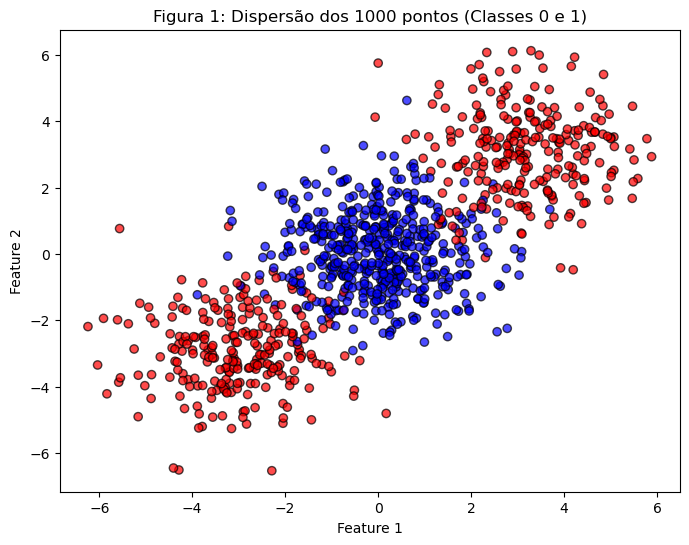

Acurácia da linha de base (Regressão Logística) no teste: 47.50%


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs, make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

# Fixando a semente globalmente
rng = np.random.default_rng(42)

# A - Gerando os dados
centers = np.array([[0., 0.], [3., 3.], [-3., -3.]])
X, c = make_blobs(n_samples=[500, 250, 250], centers=centers,
                  cluster_std=1.2, random_state=42)
y = (c > 0).astype(int) # classe 0: 1 grupo | classe 1: 2 grupos

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Figura 1
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', alpha=0.7, edgecolor='k')
plt.title('Figura 1: Dispersão dos 1000 pontos (Classes 0 e 1)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

# B - Linha de base linear (Regressão Logística)
baseline_model = LogisticRegression(random_state=42)
baseline_model.fit(X_train, y_train)
baseline_acc = baseline_model.score(X_test, y_test)
print(f"Acurácia da linha de base (Regressão Logística) no teste: {baseline_acc * 100:.2f}%")

## C - Implementação do MLP do zero

In [13]:
class MLP:
    def __init__(self, layer_sizes, output_type='binary', lr=0.01, epochs=1000):
        self.layer_sizes = layer_sizes
        self.output_type = output_type
        self.lr = lr
        self.epochs = epochs
        self.params = {}
        self.L = len(layer_sizes) - 1
        self.history = []

        # Inicialização He/Xavier simples
        for l in range(1, self.L + 1):
            self.params[f'W{l}'] = rng.standard_normal((layer_sizes[l-1], layer_sizes[l])) * np.sqrt(2. / layer_sizes[l-1])
            self.params[f'b{l}'] = np.zeros((1, layer_sizes[l]))

    def relu(self, Z):
        return np.maximum(0, Z)

    def relu_deriv(self, Z):
        return (Z > 0).astype(float)

    def sigmoid(self, Z):
        Z = np.clip(Z, -500, 500)
        return 1 / (1 + np.exp(-Z))

    def softmax(self, Z):
        expZ = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return expZ / np.sum(expZ, axis=1, keepdims=True)

    def compute_loss(self, Y_hat, Y):
        m = Y.shape[0]
        if self.output_type == 'binary':
            # Entropia cruzada binária
            Y_hat = np.clip(Y_hat, 1e-15, 1 - 1e-15)
            loss = - (1/m) * np.sum(Y * np.log(Y_hat) + (1 - Y) * np.log(1 - Y_hat))
        else:
            # Entropia cruzada categórica
            Y_hat = np.clip(Y_hat, 1e-15, 1 - 1e-15)
            loss = - (1/m) * np.sum(Y * np.log(Y_hat))
        return loss

    def fit(self, X, Y):
        m = X.shape[0]

        for epoch in range(self.epochs):
            cache = {'A0': X}
            for l in range(1, self.L):
                Z = np.dot(cache[f'A{l-1}'], self.params[f'W{l}']) + self.params[f'b{l}']
                cache[f'Z{l}'] = Z
                cache[f'A{l}'] = self.relu(Z)

            # Camada de saída
            ZL = np.dot(cache[f'A{self.L-1}'], self.params[f'W{self.L}']) + self.params[f'b{self.L}']
            cache[f'Z{self.L}'] = ZL
            if self.output_type == 'binary':
                AL = self.sigmoid(ZL)
                Y_true = Y.reshape(-1, 1)
            else:
                AL = self.softmax(ZL)
                Y_true = Y 

            cache[f'A{self.L}'] = AL

            # Calcula Perda
            loss = self.compute_loss(AL, Y_true)
            self.history.append(loss)

            # Passagem Reversa 
            grads = {}

            # Gradiente da camada de saída (Z) para cross-entropy + sigmoid/softmax é (A - Y)
            dZ = AL - Y_true
            grads[f'dW{self.L}'] = (1/m) * np.dot(cache[f'A{self.L-1}'].T, dZ)
            grads[f'db{self.L}'] = (1/m) * np.sum(dZ, axis=0, keepdims=True)

            # Propagação para as camadas ocultas
            for l in reversed(range(1, self.L)):
                dA = np.dot(dZ, self.params[f'W{l+1}'].T)
                dZ = dA * self.relu_deriv(cache[f'Z{l}'])
                grads[f'dW{l}'] = (1/m) * np.dot(cache[f'A{l-1}'].T, dZ)
                grads[f'db{l}'] = (1/m) * np.sum(dZ, axis=0, keepdims=True)

            # Atualização dos Parâmetros
            for l in range(1, self.L + 1):
                self.params[f'W{l}'] -= self.lr * grads[f'dW{l}']
                self.params[f'b{l}'] -= self.lr * grads[f'db{l}']

    def predict(self, X):
        A = X
        for l in range(1, self.L):
            Z = np.dot(A, self.params[f'W{l}']) + self.params[f'b{l}']
            A = self.relu(Z)

        ZL = np.dot(A, self.params[f'W{self.L}']) + self.params[f'b{self.L}']
        if self.output_type == 'binary':
            AL = self.sigmoid(ZL)
            return (AL > 0.5).astype(int).flatten()
        else:
            AL = self.softmax(ZL)
            return np.argmax(AL, axis=1)

Arquitetura: [2, 8, 1] | Taxa de Aprendizado: 0.1 | Épocas: 2000
Acurácia do MLP no teste: 92.50%


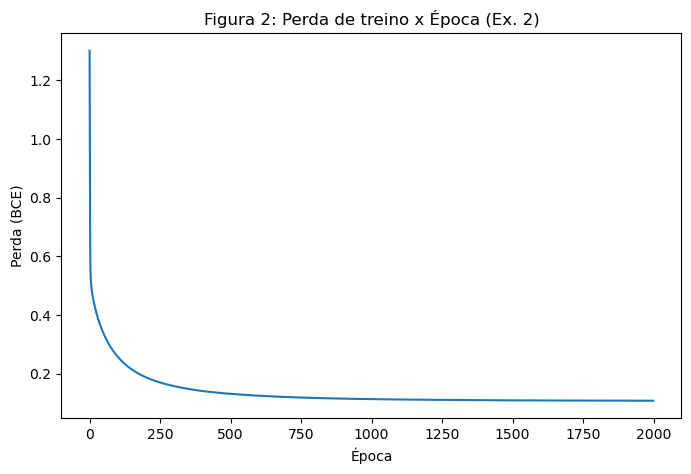

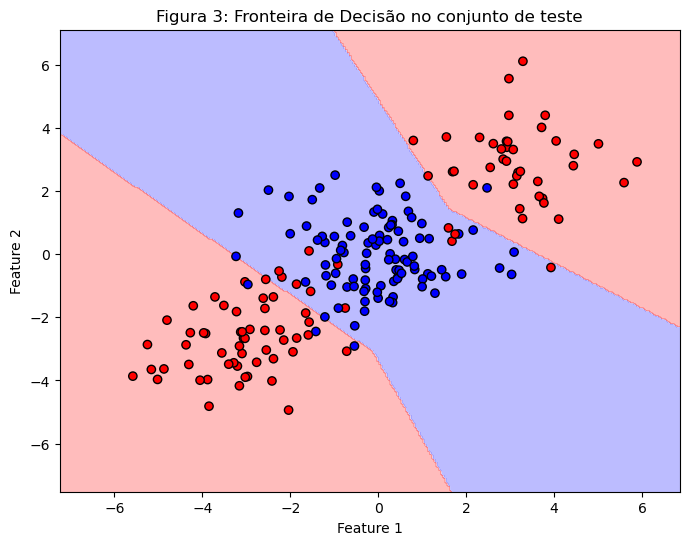

In [14]:
# Arquitetura: 2 entradas -> 8 ocultos -> 1 saída
mlp_bin = MLP(layer_sizes=[2, 8, 1], output_type='binary', lr=0.1, epochs=2000)
mlp_bin.fit(X_train, y_train)

# Avaliação
y_pred_mlp = mlp_bin.predict(X_test)
mlp_acc = accuracy_score(y_test, y_pred_mlp)
print(f"Arquitetura: [2, 8, 1] | Taxa de Aprendizado: 0.1 | Épocas: 2000")
print(f"Acurácia do MLP no teste: {mlp_acc * 100:.2f}%")

# Figura 2: Perda de treino
plt.figure(figsize=(8, 5))
plt.plot(mlp_bin.history)
plt.title('Figura 2: Perda de treino x Época (Ex. 2)')
plt.xlabel('Época')
plt.ylabel('Perda (BCE)')
plt.show()

# Figura 3: Fronteira de Decisão
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))
Z = mlp_bin.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='bwr')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='bwr', edgecolor='k')
plt.title('Figura 3: Fronteira de Decisão no conjunto de teste')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

## D - Análise 
1. **Por que a linha de base linear falha**: A Classe 1 é formada por dois grupos, um em (3, 3) e outro em (-3, -3), e a Classe 0 fica bem no meio, em (0, 0). Ou seja, a Classe 0 fica no meio entre os dois grupos da Classe 1. Com isso, uma reta só consegue separar os dados em dois lados, então não existe reta que deixe a Classe 0 de um lado e os dois grupos da Classe 1 do outro.

2. **Por que o MLP resolve**: Com 8 neurônios ocultos, a rede junta vários pedaços de reta e consegue desenhar uma faixa diagonal só em volta da Classe 0, deixando os dois grupos da Classe 1 de fora (Figura 3). Desta forma, teve-se uma acurácia no teste de 92.50%. Mesmo que, ainda alguns pontos que estão no meio das classes não consigam ser separados corretamente, além de ter pontos nas bordas.

# Exercício 3: Multiclasse, a mesma rede

## A, B e C - Geração de dados, Derivação da Softmax e Treino
**Derivação de $\frac{\partial L}{\partial z}$ (Softmax + Entropia Cruzada Categórica):**

Definições, com $\mathbf{y}$ em one-hot ($\sum_k y_k = 1$):

$$\hat{y}_k = \frac{e^{z_k}}{\sum_j e^{z_j}}, \qquad L = -\sum_k y_k \ln \hat{y}_k$$

**1. Derivada da perda:**

$$\frac{\partial L}{\partial \hat{y}_k} = -\frac{y_k}{\hat{y}_k}$$

**2. Derivada da softmax:**

$$\frac{\partial \hat{y}_k}{\partial z_i} = \begin{cases} \hat{y}_i(1 - \hat{y}_i), & k = i \\ -\hat{y}_k \hat{y}_i, & k \neq i \end{cases}$$

**3. Regra da cadeia** (somando sobre todas as saídas $k$):

$$\frac{\partial L}{\partial z_i} = \sum_k \frac{\partial L}{\partial \hat{y}_k}\frac{\partial \hat{y}_k}{\partial z_i} = -\frac{y_i}{\hat{y}_i}\hat{y}_i(1-\hat{y}_i) + \sum_{k \neq i}\left(-\frac{y_k}{\hat{y}_k}\right)(-\hat{y}_k\hat{y}_i)$$

$$= -y_i(1-\hat{y}_i) + \hat{y}_i\sum_{k \neq i} y_k = -y_i + y_i\hat{y}_i + \hat{y}_i(1 - y_i)$$

$$\boxed{\frac{\partial L}{\partial z_i} = \hat{y}_i - y_i}$$

Arquitetura: [4, 12, 3] | LR: 0.05 | Épocas: 3000
Acurácia Linha de Base (RL): 66.33%
Acurácia MLP no teste: 85.67%


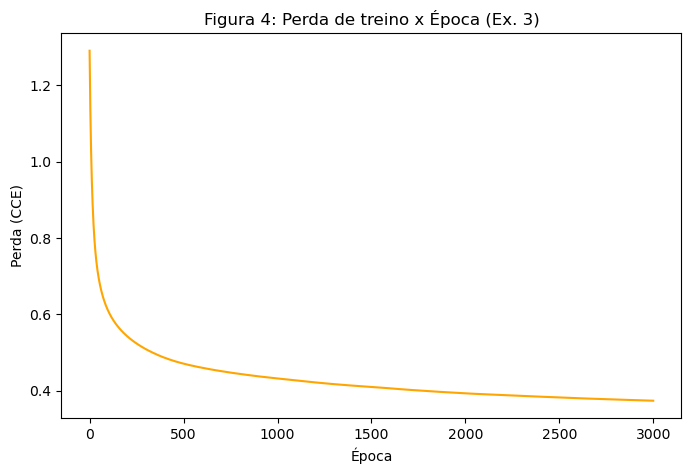

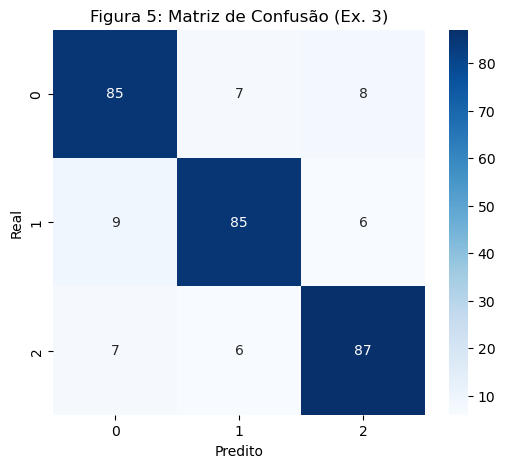

In [15]:
# A - Gerando dados
X_multi, y_multi = make_classification(n_samples=1500, n_features=4, n_informative=4,
                           n_redundant=0, n_repeated=0, n_classes=3,
                           n_clusters_per_class=2, class_sep=1.0,
                           random_state=42)

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42, stratify=y_multi)

# Convertendo y para one-hot para o treino do MLP
def to_one_hot(Y, num_classes):
    return np.eye(num_classes)[Y]

Y_train_oh = to_one_hot(y_train_m, 3)

# C - Treino e Figuras
# Arquitetura: 4 entradas -> 12 ocultos -> 3 saídas
mlp_multi = MLP(layer_sizes=[4, 12, 3], output_type='multi', lr=0.05, epochs=3000)
mlp_multi.fit(X_train_m, Y_train_oh)

y_pred_m = mlp_multi.predict(X_test_m)
acc_multi = accuracy_score(y_test_m, y_pred_m)

# Linha de Base (Regressão Logística)
lr_multi = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_m, y_train_m)
acc_multi_baseline = lr_multi.score(X_test_m, y_test_m)

print(f"Arquitetura: [4, 12, 3] | LR: 0.05 | Épocas: 3000")
print(f"Acurácia Linha de Base (RL): {acc_multi_baseline * 100:.2f}%")
print(f"Acurácia MLP no teste: {acc_multi * 100:.2f}%")

# Figura 4
plt.figure(figsize=(8, 5))
plt.plot(mlp_multi.history, color='orange')
plt.title('Figura 4: Perda de treino x Época (Ex. 3)')
plt.xlabel('Época')
plt.ylabel('Perda (CCE)')
plt.show()

# Figura 5: Matriz de Confusão
cm = confusion_matrix(y_test_m, y_pred_m)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Figura 5: Matriz de Confusão (Ex. 3)')
plt.xlabel('Predito')
plt.ylabel('Real')
plt.show()

## D - Análise 
1. **Par mais confundido**: Pela Figura 5, o par mais confundido foi Classe 0 e Classe 1, com 16 erros cruzados (7 + 9). Por mais, da diferença ser pequena, pois 0 e 2 tiveram 15 e 1 e 2 tiveram 12, com isso temos então, que os erros ficaram bem espalhados entre as classes.

2. **Motivo espacial**: Cada classe tem dois grupos de pontos e a separação entre as classes é pequena. Com isso, os grupos de classes diferentes ficam perto uns dos outros e se sobrepõem, e os pontos nessa região de sobreposição acabam sendo classificados de forma errada. Desta forma, explica-se o por que da MLP parar em 85.67%, mas ainda ficando bem acima da regressão logística de 66.33%.

# Exercício 4: Uma segunda camada oculta ajuda?

Acurácia Média Rasa (1 oculta): 85.33%
Acurácia Média Profunda (2 ocultas): 84.44%


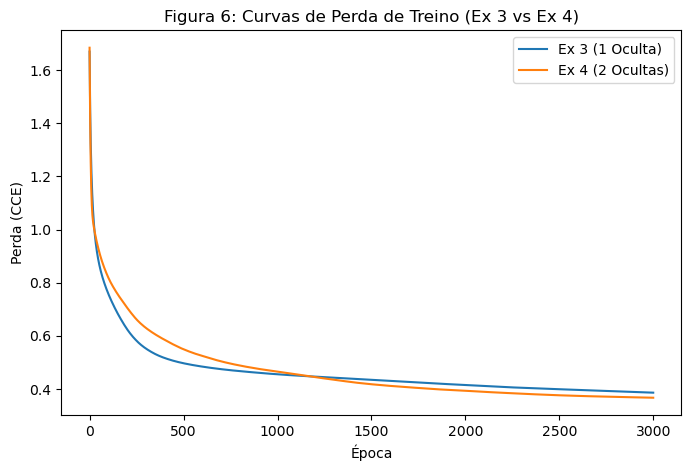

In [16]:
# Testando com 3 sementes diferentes (4, 12, 3) vs (4, 8, 8, 3)
seeds = [10, 42, 99]
acc_shallow_list = []
acc_deep_list = []
loss_shallow = None
loss_deep = None

for s in seeds:
    # Semente interna fixada para as inicializações dentro do loop
    rng = np.random.default_rng(s)

    # Rasa
    m_shallow = MLP(layer_sizes=[4, 12, 3], output_type='multi', lr=0.05, epochs=3000)
    m_shallow.fit(X_train_m, Y_train_oh)
    acc_s = accuracy_score(y_test_m, m_shallow.predict(X_test_m))
    acc_shallow_list.append(acc_s)

    # Profunda
    m_deep = MLP(layer_sizes=[4, 8, 8, 3], output_type='multi', lr=0.05, epochs=3000)
    m_deep.fit(X_train_m, Y_train_oh)
    acc_d = accuracy_score(y_test_m, m_deep.predict(X_test_m))
    acc_deep_list.append(acc_d)

    # Salvar uma das curvas para o gráfico (ex: a última semente)
    loss_shallow = m_shallow.history
    loss_deep = m_deep.history

mean_shallow = np.mean(acc_shallow_list)
mean_deep = np.mean(acc_deep_list)

print(f"Acurácia Média Rasa (1 oculta): {mean_shallow * 100:.2f}%")
print(f"Acurácia Média Profunda (2 ocultas): {mean_deep * 100:.2f}%")

# Figura 6
plt.figure(figsize=(8, 5))
plt.plot(loss_shallow, label='Ex 3 (1 Oculta)')
plt.plot(loss_deep, label='Ex 4 (2 Ocultas)')
plt.title('Figura 6: Curvas de Perda de Treino (Ex 3 vs Ex 4)')
plt.xlabel('Época')
plt.ylabel('Perda (CCE)')
plt.legend()
plt.show()

# Retornando a semente padrão para evitar conflitos posteriores
rng = np.random.default_rng(42)

## C - Análise 
1. **A segunda camada ajudou?**: Não, a rede com duas camadas ocultas teve uma média de 84.44%, contra 85.33% da rede com uma camada.

2. **Por que não melhorou**: O limite da acurácia vem da sobreposição dos grupos nos dados, e uma rede maior não resolve isso. Além disso, a rede profunda ainda tem mais parâmetros, com isso, é mais difícil de otimizar os resultados, então a camada extra aumentou o custo sem melhorar o resultado da análise.

---

# Resumo dos resultados

| # | Quantidade | Valor |
|---|---|---|
| 1 | Ex. 1 — $\mathbf{z}^{(1)}$ e $\mathbf{h}^{(1)}$ | $\mathbf{z}^{(1)} = [0.2700, -0.1800]^T$, $\mathbf{h}^{(1)} = [0.2636, -0.1781]^T$ |
| 2 | Ex. 1 — $u^{(2)}$, $\hat{y}$ e $L$ | $u^{(2)} = 0.3852$, $\hat{y} = 0.3672$, $L = 0.2002$ |
| 3 | Ex. 1 — os parâmetros atualizados | $\mathbf{W}^{(1)} = \begin{bmatrix} 0.3382 & -0.1153 \\ 0.1761 & 0.4095 \end{bmatrix}$, $\mathbf{b}^{(1)} = [0.1764, -0.2477]^T$, $\mathbf{W}^{(2)} = [0.5433, -0.3292]$, $b^{(2)} = 0.3642$ (a perda cai para $0.0965$) |
| 4 | Ex. 2 — acurácia da linha de base linear | 47.50% |
| 5 | Ex. 2 — arquitetura e acurácia no teste | [2, 8, 1], 92.50% |
| 6 | Ex. 3 — arquitetura e acurácia no teste | [4, 12, 3], 85.67% |
| 7 | Ex. 3 — par de classes mais confundido | Classes 0 e 1 (16 erros cruzados: 7 + 9) |
| 8 | Ex. 4 — arquitetura e acurácia no teste | [4, 8, 8, 3], média de 3 sementes: 84.44% |
| 9 | Ex. 4 — diferença de acurácia em relação ao Ex. 3 | −1.23 p.p. (piorou levemente: 84.44% vs 85.67%); contra a média rasa das mesmas 3 sementes (85.33%), −0.89 p.p. |